## Results

Tables, figures and statistical tests for RQ1 and RQ2, built from the outputs of notebook 05.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
from scipy.stats import friedmanchisquare, t
from sklearn.metrics import roc_auc_score

PROCESSED = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")

GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
CUTOFF = {"toddler": 3, "child": 6, "adolescent": 6, "adult": 6}
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "EBM", "TabPFN"]
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "brier"]

COLUMN, PAGE = 3.5, 7.16  # width of one column and of a full page in the IEEE format (inches)
sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})
SHORT = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB",
         "LightGBM": "LGBM", "EBM": "EBM", "TabPFN": "TabPFN"}

# the results that notebook 05 saved
cv = pd.read_csv(TABLES / "cv_folds.csv")
cross = pd.read_csv(TABLES / "cross_source.csv")

### Records per dataset

Number of records left in each dataset after cleaning (notebook 03). The first four are the main datasets. The last two are only used for the cross-source test.

In [2]:
# how many records each cleaned dataset has, and how many of them have ASD traits
rows = []
for name in GROUPS + ["toddler_saudi", "adult_kaggle"]:
    df = pd.read_csv(PROCESSED / f"{name}.csv")
    rows.append({"dataset": name, "records": len(df), "ASD traits": int(df["asd"].sum()),
                 "no ASD traits": int((df["asd"] == 0).sum()), "% ASD traits": round(100 * df["asd"].mean(), 1)})
sizes = pd.DataFrame(rows)
sizes.to_csv(TABLES / "dataset_sizes.csv", index=False)
sizes

,dataset,records,ASD traits,no ASD traits,% ASD traits
0,toddler,973,690,283,70.9
1,child,280,133,147,47.5
2,adolescent,101,60,41,59.4
3,adult,691,185,506,26.8
4,toddler_saudi,443,306,137,69.1
5,adult_kaggle,606,129,477,21.3


### 1. Main results (mean ± standard deviation over 15 test folds)

Lower is better for the Brier score; higher is better for everything else.

In [3]:
grouped = cv.groupby(["group", "model"])[METRICS]
# write each cell as "mean ± std"
table = grouped.mean().round(3).astype(str) + " ± " + grouped.std().round(3).astype(str)
table = table.reindex(pd.MultiIndex.from_product([GROUPS, MODEL_NAMES], names=["group", "model"]))
table.to_csv(TABLES / "main_results.csv")
table

accuracy      precision         recall  \
group      model                                                              
toddler    Logistic Regression  0.999 ± 0.002      1.0 ± 0.0  0.999 ± 0.003   
           Random Forest        0.962 ± 0.015  0.969 ± 0.017   0.978 ± 0.01   
           XGBoost              0.986 ± 0.009  0.993 ± 0.006  0.987 ± 0.009   
           LightGBM             0.977 ± 0.015  0.987 ± 0.012   0.98 ± 0.013   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
child      Logistic Regression  0.999 ± 0.005  0.998 ± 0.009      1.0 ± 0.0   
           Random Forest        0.938 ± 0.031  0.921 ± 0.051  0.955 ± 0.041   
           XGBoost              0.949 ± 0.034  0.932 ± 0.059  0.967 ± 0.038   
           LightGBM             0.949 ± 0.046  0.943 ± 0.058  0.952 ± 0.046   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN               0.987 ± 0.014  0.983 ± 0.026   0.99 ± 0.017   
adolescent Logistic Regression   0.918 ± 0.05  0.905 ± 0.077  0.972 ± 0.051   
           Random Forest        0.892 ± 0.064  0.879 ± 0.073  0.956 ± 0.062   
           XGBoost              0.878 ± 0.051   0.87 ± 0.053  0.939 ± 0.074   
           LightGBM             0.888 ± 0.047  0.884 ± 0.054  0.939 ± 0.067   
           EBM                  0.937 ± 0.054   0.936 ± 0.07  0.967 ± 0.053   
           TabPFN               0.931 ± 0.048  0.923 ± 0.075  0.972 ± 0.041   
adult      Logistic Regression      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           Random Forest        0.972 ± 0.021  0.956 ± 0.047  0.941 ± 0.048   
           XGBoost              0.981 ± 0.011  0.956 ± 0.037  0.977 ± 0.023   
           LightGBM             0.968 ± 0.016  0.951 ± 0.033   0.93 ± 0.048   
           EBM                      1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      1.0 ± 0.0   

                                           f1        roc_auc          brier  
group      model                                                             
toddler    Logistic Regression  0.999 ± 0.002      1.0 ± 0.0  0.008 ± 0.007  
           Random Forest         0.973 ± 0.01  0.995 ± 0.003  0.035 ± 0.004  
           XGBoost               0.99 ± 0.006  0.999 ± 0.001  0.013 ± 0.005  
           LightGBM             0.984 ± 0.011  0.998 ± 0.002  0.018 ± 0.007  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN                   1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
child      Logistic Regression  0.999 ± 0.005      1.0 ± 0.0  0.028 ± 0.035  
           Random Forest         0.937 ± 0.03  0.988 ± 0.012  0.075 ± 0.011  
           XGBoost              0.948 ± 0.033  0.992 ± 0.012  0.037 ± 0.023  
           LightGBM             0.947 ± 0.046   0.99 ± 0.014  0.043 ± 0.036  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN               0.986 ± 0.015      1.0 ± 0.0  0.011 ± 0.005  
adolescent Logistic Regression   0.934 ± 0.04  0.988 ± 0.017  0.073 ± 0.046  
           Random Forest        0.913 ± 0.051   0.977 ± 0.02  0.085 ± 0.017  
           XGBoost              0.901 ± 0.044  0.965 ± 0.022  0.081 ± 0.027  
           LightGBM             0.908 ± 0.041  0.964 ± 0.025  0.089 ± 0.041  
           EBM                  0.949 ± 0.044  0.986 ± 0.016  0.051 ± 0.045  
           TabPFN               0.945 ± 0.037   0.99 ± 0.013   0.047 ± 0.02  
adult      Logistic Regression      1.0 ± 0.0      1.0 ± 0.0  0.004 ± 0.004  
           Random Forest        0.947 ± 0.039  0.996 ± 0.005   0.034 ± 0.01  
           XGBoost              0.966 ± 0.019  0.998 ± 0.002  0.015 ± 0.005  
           LightGBM              0.94 ± 0.031  0.997 ± 0.003  0.023 ± 0.009  
           EBM                      1.0 ± 0.0      1.0 ± 0.0      0.0 ± 0.0  
           TabPFN               

### 1b. PR-AUC and calibration

Two more checks on the saved predictions from notebook 05.

* **PR-AUC** (area under the precision-recall curve). It looks only at the positive class, so it is a better guide than ROC-AUC when the classes are unbalanced (71 % of toddlers are positive, but only 27 % of adults). A model that guesses gets a PR-AUC equal to the share of positive cases, shown in the `chance` column.
* **Calibration**: can the model's percentages be trusted? If a model says 80 % for a group of people, about 80 % of them should really be positive. **ECE** (expected calibration error) is the average gap between what the model says and what is true. 0 is perfect.

Each person is predicted once in each of the 3 repeats. PR-AUC is computed for each repeat and then averaged. ECE uses all predictions together.

In [4]:
import numpy as np
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score

# predictions saved by notebook 05. "row" is the row number in the cleaned dataset
preds = pd.read_csv(TABLES / "cv_predictions.csv")
labels = {g: pd.read_csv(PROCESSED / f"{g}.csv")["asd"].values for g in GROUPS}
# add the true label to every prediction
preds["asd"] = [labels[g][r] for g, r in zip(preds["group"], preds["row"])]


# ECE = Expected Calibration Error.
# The predictions are put into 10 boxes by their probability (0-10%, 10-20%, ...).
# In each box we compare the average probability with the real share of positive cases.
# Example: a box with an average of 80% where 70% are really positive has a gap of 0.10
def ece(y, prob, bins=10):
    box = np.minimum((prob * bins).astype(int), bins - 1)
    total = 0
    for b in range(bins):
        inside = box == b
        if inside.any():
            # bigger boxes count more
            total += inside.mean() * abs(y[inside].mean() - prob[inside].mean())
    return total


rows = []
for (g, m), part in preds.groupby(["group", "model"], sort=False):
    # average_precision_score is the PR-AUC in scikit-learn
    pr = [average_precision_score(r["asd"], r["prob"]) for _, r in part.groupby("repeat")]
    rows.append({"group": g, "model": m, "pr_auc": np.mean(pr), "pr_auc std": np.std(pr, ddof=1),
                 "chance": part["asd"].mean(), "ece": ece(part["asd"].values, part["prob"].values)})
extra = pd.DataFrame(rows)
extra.to_csv(TABLES / "pr_auc_calibration.csv", index=False)
extra.set_index(["group", "model"]).round(3)

pr_auc  pr_auc std  chance    ece
group      model                                                 
toddler    Logistic Regression   1.000       0.000   0.709  0.038
           Random Forest         0.998       0.000   0.709  0.056
           XGBoost               1.000       0.000   0.709  0.017
           LightGBM              0.999       0.000   0.709  0.014
           EBM                   1.000       0.000   0.709  0.000
           TabPFN                1.000       0.000   0.709  0.004
child      Logistic Regression   1.000       0.000   0.475  0.096
           Random Forest         0.986       0.003   0.475  0.144
           XGBoost               0.989       0.004   0.475  0.029
           LightGBM              0.983       0.012   0.475  0.026
           EBM                   1.000       0.000   0.475  0.000
           TabPFN                1.000       0.000   0.475  0.023
adolescent Logistic Regression   0.985       0.005   0.594  0.102
           Random Forest         0.984       0.002   0.594  0.123
           XGBoost               0.972       0.004   0.594  0.038
           LightGBM              0.964       0.005   0.594  0.069
           EBM                   0.986       0.002   0.594  0.052
           TabPFN                0.991       0.003   0.594  0.040
adult      Logistic Regression   1.000       0.000   0.268  0.025
           Random Forest         0.988       0.003   0.268  0.071
           XGBoost               0.994       0.000   0.268  0.012
           LightGBM              0.989       0.005   0.268  0.017
           EBM                   1.000       0.000   0.268  0.000
           TabPFN                1.000       0.000   0.268  0.007

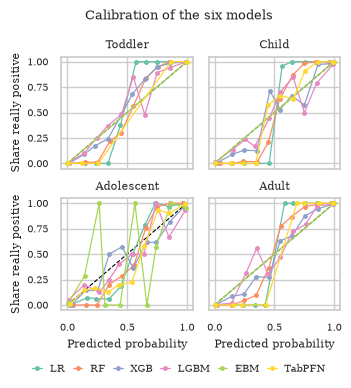

In [5]:
# calibration plot. A model on the dashed line gives percentages that match the truth
palette = dict(zip(MODEL_NAMES, sns.color_palette("Set2", 6)))

fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.6), sharex=True, sharey=True)
for i, (ax, g) in enumerate(zip(axes.flat, GROUPS)):
    ax.plot([0, 1], [0, 1], ls="--", lw=0.8, color="black")
    for m in MODEL_NAMES:
        part = preds[(preds.group == g) & (preds.model == m)]
        # 10 boxes of equal width. Empty boxes are left out
        true_share, mean_prob = calibration_curve(part["asd"], part["prob"], n_bins=10)
        ax.plot(mean_prob, true_share, marker="o", ms=2.5, lw=0.9, color=palette[m], label=SHORT[m])
    ax.set_title(g.capitalize())
    ax.set_xlabel("Predicted probability" if i >= 2 else "")
    ax.set_ylabel("Share really positive" if i % 2 == 0 else "")
fig.suptitle("Calibration of the six models")
fig.tight_layout()
# one legend under the four plots
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles[:6], names[:6], loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=6, frameon=False,
           columnspacing=0.8, handlelength=1)
fig.savefig(FIGURES / "fig_calibration.png")

**How to read this.** For toddlers, children and adults the EBM and TabPFN are both sharp and well calibrated: almost all of their predictions are close to 0 % or close to 100 %, and they are right (ECE 0.000–0.023). The EBM line lies on top of the dashed line. Logistic Regression ranks people perfectly (PR-AUC 1.000) but its percentages are less exact (ECE up to 0.10 for children): it says 60 % for people who are in fact all positive. So for these three groups the EBM gives the most trustworthy percentages.

For adolescents every model is less well calibrated (ECE 0.04–0.12). The lines jump because the middle boxes hold only a few predictions each.

PR-AUC is far above the chance level in every group, including adults where only 27 % are positive. So the high ROC-AUC values are not caused by the class imbalance.

### 2. Baseline: the scoring rule itself

Before reading the model scores, compare them with simply adding up the ten answers and applying the cut-off. No learning is involved.

In [6]:
rows = []
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    # no model here. Only add up the answers and compare with the cut-off
    pred = (df[QUESTIONS].sum(axis=1) > CUTOFF[g]).astype(int)
    rows.append({"group": g, "records": len(df), "accuracy": (pred == df["asd"]).mean(),
                 "errors": int((pred != df["asd"]).sum())})
pd.DataFrame(rows)

,group,records,accuracy,errors
0,toddler,973,1.0,0
1,child,280,1.0,0
2,adolescent,101,1.0,0
3,adult,691,1.0,0


The rule is right 100 % of the time, because it *is* the label. Every model is therefore being measured on how closely it recovers a known formula from a few hundred examples. That is still a fair way to **compare** the models, but it is not evidence that any of them can detect autism.

### 2b. Sanity checks

Two controls to show that the perfect scores come from the data and not from a mistake in the code.

**Check 1: shuffled labels.** The labels are mixed up at random and the same model is trained again. If any information leaked from the test folds, the score would stay high. If not, it falls to chance (ROC-AUC about 0.5).

**Check 2: raw files.** A plain logistic regression is trained on the **raw downloaded files**, with no cleaning at all. The hold-out split is made first, before anything else touches the data. Only the **ten answer columns** are used. The total-score column (`result` in the UCI files, `Qchat-10-Score` in the toddler file) is **not** given to the model, because the label is made from it and the check would then be trivial. The question this answers is: *does a simple model still get everything right when none of our own cleaning or pipeline code is involved?* If yes, the perfect scores are a property of the data (the label is a sum of the ten answers), not something our pipeline created.

In [7]:
import io
import re

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = QUESTIONS + ["age", "male", "jaundice", "family_asd"]
RAW = Path("../data/raw")


def read_arff(path):
    text = Path(path).read_text(encoding="latin-1")
    header, body = re.split("@data", text, flags=re.IGNORECASE)
    cols = [line.split()[1] for line in header.splitlines() if line.lower().startswith("@attribute")]
    return pd.read_csv(io.StringIO(body), header=None, names=cols, quotechar="'", na_values="?", skipinitialspace=True)


# (file, answer columns, label column)
raw = {
    "toddler": (pd.read_csv(RAW / "toddler/Toddler Autism dataset July 2018.csv"), QUESTIONS, "Class/ASD Traits "),
    "child": (read_arff(RAW / "child/Autism-Child-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
    "adolescent": (read_arff(RAW / "adolescent/Autism-Adolescent-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
    "adult": (read_arff(RAW / "adult/Autism-Adult-Data.arff"), [f"A{i}_Score" for i in range(1, 11)], "Class/ASD"),
}

rows = []
# stratified means every fold has the same share of positive cases
folds = StratifiedKFold(5, shuffle=True, random_state=0)
# for shuffling the labels
rng = np.random.RandomState(0)
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    real = cross_val_score(lr, df[FEATURES], df["asd"], cv=folds, scoring="roc_auc").mean()
    # same model, but the labels are mixed up. The score should drop to about 0.5 (guessing)
    shuffled = cross_val_score(lr, df[FEATURES], rng.permutation(df["asd"]), cv=folds, scoring="roc_auc").mean()

    # now the raw file, with no cleaning at all
    rdf, qcols, ycol = raw[g]
    y = rdf[ycol].astype(str).str.strip().str.lower().eq("yes").astype(int).values
    # we use only the ten answers, not the total score column
    X = rdf[qcols].astype(int).values
    idx = np.random.RandomState(7).permutation(len(rdf))
    # mix the rows. The first 20% is the test set, the rest is for training
    test, train = idx[:len(rdf) // 5], idx[len(rdf) // 5:]
    # no scaling and no SMOTE (making extra rows for the smaller class) here, to keep this check simple
    prob = LogisticRegression(max_iter=5000).fit(X[train], y[train]).predict_proba(X[test])[:, 1]
    rows.append({"group": g, "LR AUC, real labels": real, "LR AUC, shuffled labels": shuffled,
                 "raw hold-out AUC": roc_auc_score(y[test], prob),
                 "raw hold-out errors": int(((prob >= 0.5) != y[test]).sum()), "raw hold-out size": len(test)})

sanity = pd.DataFrame(rows).set_index("group")
sanity.to_csv(TABLES / "sanity_checks.csv")
sanity.round(3)

,"LR AUC, real labels","LR AUC, shuffled labels",raw hold-out AUC,raw hold-out errors,raw hold-out size
group,,,,,
toddler,1.000,0.523,1.0,0,210
child,1.000,0.502,1.0,0,58
adolescent,0.985,0.472,1.0,0,20
adult,1.000,0.508,1.0,0,140


### 3. Spread across folds

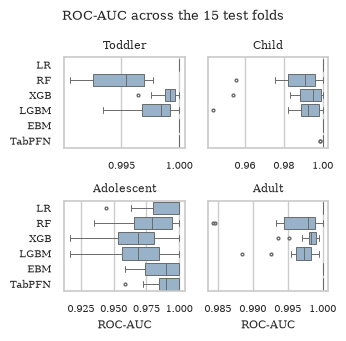

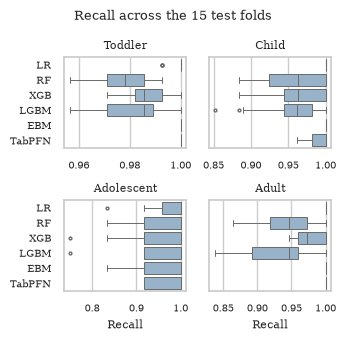

In [8]:
# short model names fit better in the plot
plot = cv.assign(model=cv.model.map(SHORT))

for metric, label in [("roc_auc", "ROC-AUC"), ("recall", "Recall")]:
    fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.4), sharey=True)
    for i, (ax, g) in enumerate(zip(axes.flat, GROUPS)):
        sns.boxplot(plot[plot.group == g], x=metric, y="model", order=SHORT.values(),
                    color="#8fb3d1", linewidth=0.7, fliersize=2, ax=ax)
        ax.set_title(g.capitalize())
        ax.set_xlabel(label if i >= 2 else "")
        ax.set_ylabel("")
    fig.suptitle(f"{label} across the 15 test folds")
    fig.tight_layout()
    fig.savefig(FIGURES / f"fig_cv_{metric}.png")

### 4. Are the differences real?

**Friedman test** (from the proposal): within each age group, are the six models' fold scores different overall? The 15 folds act as the blocks. **Kendall's W** is the effect size for this test. It goes from 0 (the models are ranked differently in every fold) to 1 (the models are ranked the same way in every fold).

Two cautions. The Friedman and Nemenyi tests were designed for blocks that are independent, usually separate datasets. Here the blocks are 15 folds of the **same** dataset, and folds from repeated cross-validation share training data. So the p-values come out too small, and these two tests are shown only as a description of the ranking.

For the two models this study focuses on, EBM and TabPFN, a **corrected resampled t-test** (Nadeau & Bengio, 2003) is used for the actual conclusions. It makes the variance bigger to account for the shared training data. Because nine comparisons are made in each age group, the p-values are also adjusted with the **Holm correction**, and an effect size is reported next to each one.

In [9]:
rows = []
for g in GROUPS:
    for metric in ["roc_auc", "f1"]:
        # one row for each fold, one column for each model
        wide = cv[cv.group == g].pivot(index="fold", columns="model", values=metric)[MODEL_NAMES]
        # Friedman compares ranks, so the scores do not need a normal distribution (ANOVA needs that)
        stat, p = friedmanchisquare(*[wide[m] for m in MODEL_NAMES])
        # Kendall's W = chi2 / (folds x (models - 1)). Close to 1 means the same ranking in every fold
        w = stat / (len(wide) * (len(MODEL_NAMES) - 1))
        rows.append({"group": g, "metric": metric, "chi2": round(stat, 2), "p": p, "Kendall W": round(w, 2)})
friedman = pd.DataFrame(rows)
friedman

,group,metric,chi2,p,Kendall W
0,toddler,roc_auc,69.51,1.293739e-13,0.93
1,toddler,f1,69.29,1.436624e-13,0.92
2,child,roc_auc,53.90,2.200630e-10,0.72
3,child,f1,55.72,9.291889e-11,0.74
4,adolescent,roc_auc,28.87,2.453743e-05,0.38
5,adolescent,f1,23.65,2.535582e-04,0.32
6,adult,roc_auc,65.25,9.940676e-13,0.87
7,adult,f1,66.16,6.449715e-13,0.88


Nemenyi post-hoc test (p-values) for ROC-AUC, to see which pairs differ. As said above, read these as a description only:

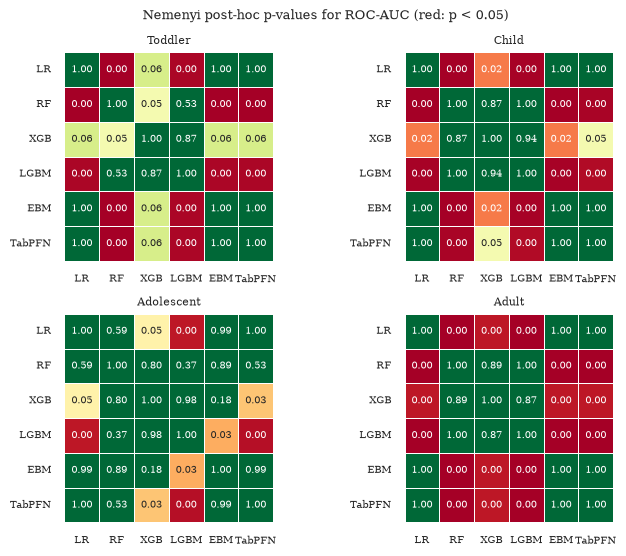

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(PAGE, 5.6))
for ax, g in zip(axes.flat, GROUPS):
    wide = cv[cv.group == g].pivot(index="fold", columns="model", values="roc_auc")[MODEL_NAMES]
    pvals = sp.posthoc_nemenyi_friedman(wide).rename(index=SHORT, columns=SHORT)
    # all p-values above 0.1 get the same colour
    sns.heatmap(pvals, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdYlGn",
                vmin=0, vmax=0.1, cbar=False, square=True, linewidths=0.4, ax=ax)
    ax.set_title(g.capitalize())
    ax.tick_params(rotation=0)
fig.suptitle("Nemenyi post-hoc p-values for ROC-AUC (red: p < 0.05)")
fig.tight_layout()
fig.savefig(FIGURES / "fig_nemenyi_roc_auc.png")

In [11]:
# t-test for cross-validation scores. test_frac is the size of a test fold (20%)
def corrected_ttest(a, b, test_frac=0.2):
    d = a - b
    # the second part makes the variance bigger, because the folds share training rows
    var = d.var(ddof=1) * (1 / len(d) + test_frac / (1 - test_frac))
    # both models have the same score in every fold
    if var == 0:
        return 0.0, 1.0
    stat = d.mean() / var ** 0.5
    # p-value for a difference in either direction
    return stat, 2 * t.sf(abs(stat), len(d) - 1)


# Holm correction. When many tests are run, some look significant only by luck.
# Holm makes the p-values bigger to allow for that: the smallest p is multiplied by the
# number of tests, the next one by one less, and so on.
# Example with 3 tests: p = 0.01, 0.04, 0.30 become 0.03, 0.08, 0.30
def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty(len(p))
    out[order] = adjusted
    return out


rows = []
for g in GROUPS:
    wide = cv[cv.group == g].pivot(index="fold", columns="model", values="roc_auc")
    for focus in ["EBM", "TabPFN"]:
        for other in MODEL_NAMES:
            # EBM against TabPFN is tested once, not twice
            if other == focus or (focus == "TabPFN" and other == "EBM"):
                continue
            stat, p = corrected_ttest(wide[focus], wide[other])
            d = wide[focus] - wide[other]
            # effect size (Cohen's d) = average difference / how much the difference changes between folds.
            # About 0.2 is small, 0.5 medium, 0.8 large
            size = d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else 0.0
            rows.append({"group": g, "model": focus, "vs": other, "AUC difference": d.mean(),
                         "effect size d": size, "p": p})

ttests = pd.DataFrame(rows)
# 9 comparisons in each age group are corrected together
ttests["p (Holm)"] = ttests.groupby("group")["p"].transform(holm)
ttests["significant"] = ttests["p (Holm)"] < 0.05
ttests.to_csv(TABLES / "corrected_ttests.csv", index=False)
ttests.round(4)

,group,model,vs,AUC difference,effect size d,p,p (Holm),significant
0,toddler,EBM,Logistic Regression,0.0000,0.0000,1.0000,1.0000,False
1,toddler,EBM,Random Forest,0.0053,2.0931,0.0023,0.0206,True
2,toddler,EBM,XGBoost,0.0010,1.0252,0.0899,0.5926,False
3,toddler,EBM,LightGBM,0.0022,1.0443,0.0847,0.5926,False
4,toddler,EBM,TabPFN,0.0000,0.0000,1.0000,1.0000,False
5,toddler,TabPFN,Logistic Regression,0.0000,0.0000,1.0000,1.0000,False
6,toddler,TabPFN,Random Forest,0.0053,2.0931,0.0023,0.0206,True
7,toddler,TabPFN,XGBoost,0.0010,1.0252,0.0899,0.5926,False
8,toddler,TabPFN,LightGBM,0.0022,1.0443,0.0847,0.5926,False
9,child,EBM,Logistic Regression,0.0000,0.0000,1.0000,1.0000,False


### 5. Missed cases

In screening, a **false negative** (a child with ASD traits sent home as "no concern") is the costliest mistake. Counts are summed over all 15 folds, so each record is counted three times (once per repeat).

In [12]:
# add up the right and wrong predictions of all 15 folds
errors = cv.groupby(["group", "model"])[["tp", "fn", "fp", "tn"]].sum()
errors = errors.reindex(pd.MultiIndex.from_product([GROUPS, MODEL_NAMES]))
errors["missed %"] = (100 * errors["fn"] / (errors["fn"] + errors["tp"])).round(2)
errors

tp  fn  fp    tn  missed %
toddler    Logistic Regression  2067   3   0   849      0.14
           Random Forest        2025  45  66   783      2.17
           XGBoost              2043  27  15   834      1.30
           LightGBM             2029  41  26   823      1.98
           EBM                  2070   0   0   849      0.00
           TabPFN               2070   0   0   849      0.00
child      Logistic Regression   399   0   1   440      0.00
           Random Forest         381  18  34   407      4.51
           XGBoost               386  13  30   411      3.26
           LightGBM              380  19  24   417      4.76
           EBM                   399   0   0   441      0.00
           TabPFN                395   4   7   434      1.00
adolescent Logistic Regression   175   5  20   103      2.78
           Random Forest         172   8  25    98      4.44
           XGBoost               169  11  26    97      6.11
           LightGBM              169  11  23   100      6.11
           EBM                   174   6  13   110      3.33
           TabPFN                175   5  16   107      2.78
adult      Logistic Regression   555   0   0  1518      0.00
           Random Forest         522  33  25  1493      5.95
           XGBoost               542  13  26  1492      2.34
           LightGBM              516  39  27  1491      7.03
           EBM                   555   0   0  1518      0.00
           TabPFN                555   0   0  1518      0.00

### 6. Cross-source results (RQ2)

The `in-source` column is the cross-validated ROC-AUC of the same model on its own training source, for comparison.

In [13]:
# the AUC of the same model on its own data, to compare
in_source = cv.groupby(["group", "model"])["roc_auc"].mean()
cross["in-source AUC"] = [in_source.get((tr, m)) for tr, m in zip(cross["train"], cross["model"])]
cross[["train", "test", "model", "roc_auc", "in-source AUC", "recall", "precision", "brier"]].round(3)

,train,test,model,roc_auc,in-source AUC,recall,precision,brier
0,toddler,toddler_saudi,Logistic Regression,1.000,1.000,1.000,1.000,0.011
1,toddler,toddler_saudi,Random Forest,0.998,0.995,0.990,0.981,0.026
2,toddler,toddler_saudi,XGBoost,1.000,0.999,0.997,1.000,0.005
3,toddler,toddler_saudi,LightGBM,1.000,0.998,0.997,0.993,0.005
4,toddler,toddler_saudi,EBM,1.000,1.000,1.000,1.000,0.000
5,toddler,toddler_saudi,TabPFN,1.000,1.000,1.000,1.000,0.000
6,toddler_saudi,toddler,Logistic Regression,1.000,NaN,1.000,1.000,0.001
7,toddler_saudi,toddler,Random Forest,0.986,NaN,0.942,0.972,0.055
8,toddler_saudi,toddler,XGBoost,0.994,NaN,0.942,0.992,0.037
9,toddler_saudi,toddler,LightGBM,0.992,NaN,0.920,0.986,0.055


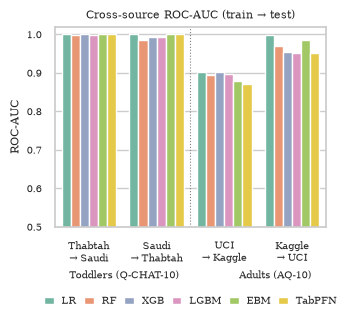

In [14]:
PAIR_NAMES = {"toddler": "Thabtah", "toddler_saudi": "Saudi", "adult": "UCI", "adult_kaggle": "Kaggle"}
plot = cross.assign(model=cross.model.map(SHORT),
                    pair=[f"{PAIR_NAMES[a]}\n→ {PAIR_NAMES[b]}" for a, b in zip(cross.train, cross.test)])

fig, ax = plt.subplots(figsize=(COLUMN, 2.6))
sns.barplot(plot, x="pair", y="roc_auc", hue="model", hue_order=SHORT.values(), palette="Set2", ax=ax)
ax.set_ylim(0.5, 1.02)
ax.set_title("Cross-source ROC-AUC (train → test)")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Toddlers (Q-CHAT-10)                    Adults (AQ-10)", fontsize=7)
# dotted line between the toddler bars and the adult bars
ax.axvline(1.5, color="grey", lw=0.8, ls=":")
sns.move_legend(ax, "upper center", bbox_to_anchor=(0.5, -0.3), ncol=6, title=None, frameon=False,
                columnspacing=0.8, handlelength=1)
fig.savefig(FIGURES / "fig_cross_source.png")

### 7. Bias check

Using the out-of-fold predictions saved in notebook 05, recall and false-positive rate are compared for the model chosen for each age group. There are **two separate groupings**: by gender and by ethnicity. They are shown as two blocks and must not be added together, because the same people are in both.

Ethnic groups with fewer than 20 records are merged into "Other/Unknown", because rates on a handful of people mean nothing. The table also shows how many positive and negative cases each subgroup has. Recall is based on the positive cases and the false-positive rate on the negative cases, so a rate that rests on about 20 people is only a rough pointer.

In [15]:
chosen = pd.read_csv("../app/data/chosen_models.csv", index_col="group")["model"]


# every person is in the predictions 3 times, once in each repeat
def rates(df):
    pos, neg = df[df.asd == 1], df[df.asd == 0]
    # positives and negatives are counted per person, so divide by the 3 repeats
    return pd.Series({"records": len(df) // 3, "positives": len(pos) // 3, "negatives": len(neg) // 3,
                      "recall": (pos.prob >= 0.5).mean() if len(pos) else None,
                      "false positive rate": (neg.prob >= 0.5).mean() if len(neg) else None})


rows = []
for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    # add the personal details to the predictions
    p = preds[(preds.group == g) & (preds.model == chosen[g])].drop(columns="asd").merge(df, left_on="row", right_index=True)
    # small ethnic groups go into one group, they are too small to measure alone
    common = p.ethnicity.value_counts()
    # 60 rows = 20 people, because every person is there 3 times
    p["ethnicity"] = (p.ethnicity.where(p.ethnicity.map(common) >= 60, "Other/Unknown")  # 20 people x 3 repeats
                                 .replace({"Other": "Other/Unknown", "Unknown": "Other/Unknown"}))
    p["gender"] = p.male.map({1: "male", 0: "female"})
    for col in ["gender", "ethnicity"]:
        for value, part in p.groupby(col):
            rows.append({"group": g, "model": chosen[g], "attribute": col, "value": value, **rates(part)})

bias = pd.DataFrame(rows)
bias.to_csv(TABLES / "bias_check.csv", index=False)
bias.set_index(["group", "model", "attribute", "value"]).round(3)

records  positives  \
group      model               attribute value                                
toddler    EBM                 gender    female            291.0      188.0   
                                         male              682.0      502.0   
                               ethnicity Asian             272.0      198.0   
                                         Black              48.0       36.0   
                                         Hispanic           37.0       29.0   
                                         Latino             26.0       20.0   
                                         Middle Eastern    167.0       94.0   
                                         Other/Unknown      52.0       44.0   
                                         South Asian        60.0       37.0   
                                         White European    311.0      232.0   
child      EBM                 gender    female             83.0       37.0   
                                         male              197.0       96.0   
                               ethnicity Asian              44.0       21.0   
                                         Middle Eastern     26.0        8.0   
                                         Other/Unknown      85.0       38.0   
                                         South Asian        21.0        8.0   
                                         White European    104.0       58.0   
adolescent Logistic Regression gender    female             52.0       34.0   
                                         male               49.0       26.0   
                               ethnicity Other/Unknown      62.0       31.0   
                                         White European     39.0       29.0   
adult      EBM                 gender    female            332.0      102.0   
                                         male              359.0       83.0   
                               ethnicity Asian             123.0       16.0   
                                         Black              43.0       18.0   
                                         Latino             20.0       10.0   
                                         Middle Eastern     90.0        8.0   
                                         Other/Unknown     152.0       25.0   
                                         South Asian        36.0        3.0   
                                         White European    227.0      105.0   

                                                         negatives  recall  \
group      model               attribute value                               
toddler    EBM                 gender    female              103.0   1.000   
                                         male                180.0   1.000   
                               ethnicity Asian                74.0   1.000   
                                         Black                12.0   1.000   
                                         Hispanic              8.0   1.000   
                                         Latino                6.0   1.000   
                                         Middle Eastern       73.0   1.000   
                                         Other/Unknown         8.0   1.000   
                                         South Asian          23.0   1.000   
                                         White European       79.0   1.000   
child      EBM                 gender    female               46.0   1.000   
                                         male                101.0   1.000   
                               ethnicity Asian                23.0   1.000   
                                         Middle Eastern       18.0   1.000   
                                         Other/Unknown        47.0   1.000   
                                         South Asian          13.0   1.000   
                                         White European       46.0   1.000   
adolescent Logistic Regression gender    femal

### 8. Answers

**RQ1: How do EBM and TabPFN compare with the established models when leakage is controlled?**

* In the toddler, child and adult data, EBM and TabPFN are **perfect or almost perfect** (ROC-AUC 1.000, recall 1.000, Brier score ≈ 0). So is plain **Logistic Regression**. All three can represent "add up the answers and compare with a cut-off" directly.
* The tree ensembles (Random Forest, XGBoost, LightGBM) are slightly behind (ROC-AUC 0.988–0.999) and **miss 1–7 % of positive cases**. Their one-feature-at-a-time splits can only approximate a sum. The Friedman test points the same way in every group (Kendall's W 0.87–0.93 for toddlers and adults, 0.72 for children, 0.38 for adolescents), but its p-values are too small here because the folds are not independent, so it is used only as a description.
* After correcting for overlapping folds and for the nine comparisons made in each group (Holm), EBM and TabPFN are significantly better than Random Forest only for toddlers (adjusted p = 0.021, a difference of 0.005 in ROC-AUC). None of the other differences are significant, and **neither model is ever better than Logistic Regression**. Many of the effect sizes look large (d around 1), but the differences behind them are tiny (0.001–0.026 in ROC-AUC): the models differ a little, in the same direction in most folds.
* **PR-AUC tells the same story as ROC-AUC.** It is 0.96–1.00 for every model in every group, far above the chance level (0.27 for adults, 0.71 for toddlers), so the results are not a side effect of the class imbalance.
* **Calibration separates the models more than ranking does.** For toddlers, children and adults the EBM has the best-calibrated probabilities (ECE 0.000), then TabPFN (0.004–0.023). Logistic Regression ranks just as well but its percentages are less exact (ECE 0.03–0.10), and Random Forest is the least calibrated (0.06–0.14). For adolescents all models are less well calibrated (0.04–0.12).
* **Adolescents** (101 records) are the hardest group for every model (ROC-AUC 0.964–0.990). TabPFN, Logistic Regression and EBM lead, but the differences are not significant.
* **Conclusion:** EBM and TabPFN match the best model in every group, which makes EBM attractive because it is also fully readable. However, they do not beat a simple logistic regression on this data, because the label is a linear rule.

**RQ2: Do the models work on data from a different source?**

* **Toddlers transfer perfectly** in both directions (Thabtah ↔ Saudi). Both datasets use the same Q-CHAT-10 scoring rule to make the label, so a model that learned the rule on one works on the other.
* **Adults do not.** Trained on UCI and tested on Kaggle, ROC-AUC drops from about 1.00 to **0.87–0.90** and precision falls to about 0.52, because the Kaggle labels follow the scoring rule only 80 % of the time. EBM (0.879) and TabPFN (0.871) are the *lowest*: the models that copy the source rule most exactly transfer worst when the rule changes.
* In the other direction (Kaggle → UCI), Logistic Regression recovers best (0.998), then EBM (0.984). TabPFN keeps a good ROC-AUC (0.952) but finds only 41 % of positive cases at the 0.5 threshold.
* **Conclusion:** cross-source performance depends on *how the labels were made*, not on the model. In-source accuracy close to 100 % says little about performance elsewhere.

**Bias check.** For toddlers, children and adults the chosen model makes no errors in any gender or ethnic group, so no bias can be measured. The point is that the label rule is applied the same way to everyone, not that the models are fair. For adolescents, the false-positive rate is higher for girls (0.24, from 18 negative cases) than for boys (0.10, from 23 negative cases), and higher for the White European group (0.33, from only 10 negative cases) than for the rest (0.11, from 31). Gender and ethnicity are two separate ways of splitting the same 101 people. With so few negative cases these rates are only a pointer for future work, not a finding.